<a href="https://colab.research.google.com/github/202401696/PSO26-2/blob/main/PSO26_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
#깃허브 데이터 불러오기
!git clone https://github.com/202401696/PSO26-2.git

fatal: destination path 'PSO26-2' already exists and is not an empty directory.


In [15]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path("PSO26-2")
files = sorted(ROOT.rglob("*_asos_*.csv"))

# 다양한 인코딩으로 CSV 파일을 안전하게 읽어오는 함수
def read_csv_auto(path):
    for enc in ["utf-8-sig", "cp949", "euc-kr", "utf-8"]:
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"지원하는 인코딩으로 읽지 못했습니다: {path}")

데이터 파일 로드 및 통합

In [16]:
all_data = []
for f in files:
    try:
        df_temp = read_csv_auto(f)
        all_data.append(df_temp)
    except Exception:
        pass

# 전체 기상 데이터 통합
df_total = pd.concat(all_data, ignore_index=True)

데이터 전처리

In [17]:
# 날짜/시간 형식 변환 및 파생 변수(연도, 월, 시간, 날짜) 생성
df_total["일시"] = pd.to_datetime(df_total["일시"], errors="coerce")
df_total["연도"] = df_total["일시"].dt.year
df_total["월"] = df_total["일시"].dt.month
df_total["시간"] = df_total["일시"].dt.hour
df_total["날짜"] = df_total["일시"].dt.date
df_total["hour"] = df_total["일시"].dt.hour # 호환성 유지용

# 숫자형 데이터 변환
df_total["기온(°C)"] = pd.to_numeric(df_total["기온(°C)"], errors="coerce")
df_total["일사(MJ/m2)"] = pd.to_numeric(df_total["일사(MJ/m2)"], errors="coerce")

# 여름철(6월~9월) 데이터 필터링 및 정제
df_summer = df_total[(df_total["월"] >= 6) & (df_total["월"] <= 9)].copy()
df_summer = df_summer.dropna(subset=["연도"])
df_summer["연도"] = df_summer["연도"].astype(int)

# 폭염일 정의 (단일 계통 기준 일별 최고기온 33°C 이상인 날)
daily_max = df_summer.groupby("날짜")["기온(°C)"].max()
heatwave_dates = daily_max[daily_max >= 33].index
df_summer["is_heatwave"] = df_summer["날짜"].isin(heatwave_dates)

파일 구조 및 결측치 검사

In [18]:
report = []
for f in files:
    try:
        df_temp = read_csv_auto(f)
        report.append({
            "파일": f.name,
            "행 수": len(df_temp),
            "열 수": len(df_temp.columns),
            "결측치 총합": int(df_temp.isna().sum().sum()),
            "열 이름": ", ".join(df_temp.columns.astype(str)),
            "읽기 상태": "성공",
        })
    except Exception as e:
        report.append({
            "파일": f.name,
            "행 수": None,
            "열 수": None,
            "결측치 총합": None,
            "열 이름": None,
            "읽기 상태": str(e),
        })

report_df = pd.DataFrame(report)
display(report_df)

,파일,행 수,열 수,결측치 총합,열 이름,읽기 상태
0,busan_asos_2016.csv,8760,9,3993,"지점, 지점명, 일시, 기온(°C), 기온 QC플래그, 습도(%), 습도 QC플래그...",성공
1,busan_asos_2017.csv,8736,9,4468,"지점, 지점명, 일시, 기온(°C), 기온 QC플래그, 습도(%), 습도 QC플래그...",성공
2,busan_asos_2018.csv,8736,9,8889,"지점, 지점명, 일시, 기온(°C), 기온 QC플래그, 습도(%), 습도 QC플래그...",성공
3,busan_asos_2019.csv,8736,9,25560,"지점, 지점명, 일시, 기온(°C), 기온 QC플래그, 습도(%), 습도 QC플래그...",성공
4,busan_asos_2020.csv,8760,9,26276,"지점, 지점명, 일시, 기온(°C), 기온 QC플래그, 습도(%), 습도 QC플래그...",성공
5,busan_asos_2021.csv,8736,9,26215,"지점, 지점명, 일시, 기온(°C), 기온 QC플래그, 습도(%), 습도 QC플래그...",성공
6,busan_asos_2022.csv,8736,9,26217,"지점, 지점명, 일시, 기온(°C), 기온 QC플래그, 습도(%), 습도 QC플래그...",성공
7,busan_asos_2023.csv,8736,9,26208,"지점, 지점명, 일시, 기온(°C), 기온 QC플래그, 습도(%), 습도 QC플래그...",성공
8,busan_asos_2024.csv,8760,9,26280,"지점, 지점명, 일시, 기온(°C), 기온 QC플래그, 습도(%), 습도 QC플래그...",성공
9,busan_asos_2025.csv,8736,9,26210,"지점, 지점명, 일시, 기온(°C), 기온 QC플래그, 습도(%), 습도 QC플래그...",성공


In [19]:
print(
    f"전체 파일 수: {len(files)}개 | 읽기 성공:"
    f" {(report_df['읽기 상태'] == '성공').sum()}개"
)

전체 파일 수: 60개 | 읽기 성공: 60개


샘플 파일(부산2025) 로드 및 기본 구조 확인용

,기온(°C)
count,2928.000000
mean,26.034939
std,3.549205
min,16.600000
25%,23.300000
50%,26.300000
75%,28.500000
max,34.500000


,지점,기온(°C),기온 QC플래그,습도(%),습도 QC플래그,일사(MJ/m2),일사 QC플래그
지점,NaN,NaN,NaN,NaN,NaN,NaN,NaN
기온(°C),NaN,1.000000,NaN,0.545446,NaN,0.246065,NaN
기온 QC플래그,NaN,NaN,NaN,NaN,NaN,NaN,NaN
습도(%),NaN,0.545446,NaN,1.000000,NaN,-0.327683,NaN
습도 QC플래그,NaN,NaN,NaN,NaN,NaN,NaN,NaN
일사(MJ/m2),NaN,0.246065,NaN,-0.327683,NaN,1.000000,NaN
일사 QC플래그,NaN,NaN,NaN,NaN,NaN,NaN,NaN


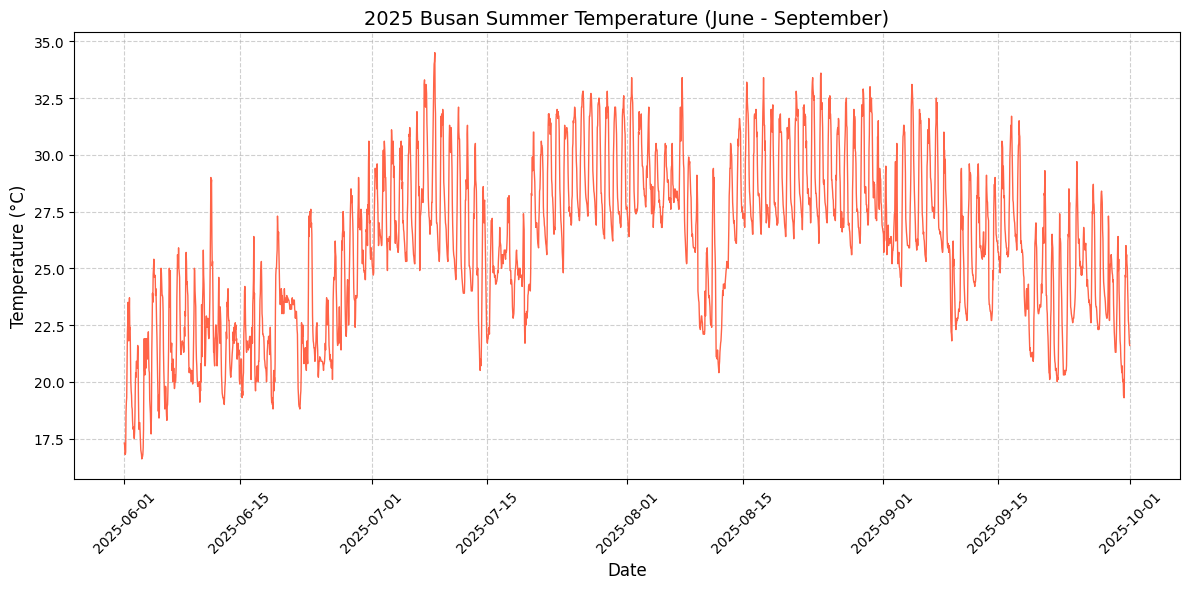

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50728 (\N{HANGUL SYLLABLE ON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


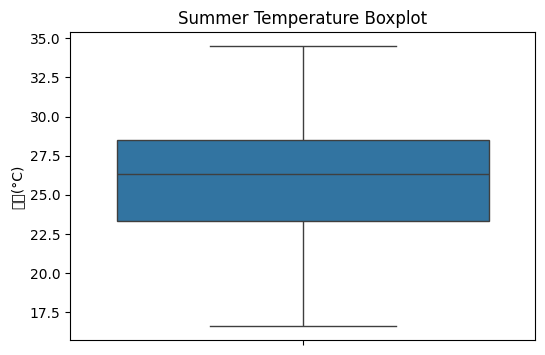

In [20]:
# 부산 2025년 기상 파일 선택 및 불러오기
sample_path = next(
    (f for f in files if "busan" in str(f).lower() and "2025" in f.name),
    files[0] if files else None,
)
df_sample = read_csv_auto(sample_path)

# 부산 2025년 데이터 정제 및 여름철 필터링
df_sample["일시"] = pd.to_datetime(df_sample["일시"], errors="coerce")
df_sample["기온(°C)"] = pd.to_numeric(df_sample["기온(°C)"], errors="coerce")
df_sample_summer = df_sample[(df_sample["일시"].dt.month >= 6) & (df_sample["일시"].dt.month <= 9)].copy()

# 여름철 기온 기술통계량 요약 출력
display(df_sample_summer["기온(°C)"].describe())

# 숫자형 컬럼 간 상관계수 확인
display(df_sample.corr(numeric_only=True))

# 부산 2025년 여름철 기온 시계열 그래프
plt.figure(figsize=(12, 6))
plt.plot(df_sample_summer["일시"], df_sample_summer["기온(°C)"], color="tomato", linewidth=1)
plt.title("2025 Busan Summer Temperature (June - September)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Temperature (°C)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 부산 2025년 여름철 이상치 확인용 박스플롯
plt.figure(figsize=(6, 4))
sns.boxplot(y=df_sample_summer["기온(°C)"])
plt.title("Summer Temperature Boxplot")
plt.show()

연도별 및 폭염/연속일수 분석

,Year,Annual Max Temp (°C)
0,2016,37.5
1,2017,36.8
2,2018,39.4
3,2019,36.7
4,2020,36.3
5,2021,36.3
6,2022,37.1
7,2023,37.6
8,2024,36.8
9,2025,37.6


,기온(°C)
기온(°C),
36,2
59,1
64,1
71,1
72,1
77,2
82,1
86,1


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50728 (\N{HANGUL SYLLABLE ON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54253 (\N{HANGUL SYLLABLE POG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50684 (\N{HANGUL SYLLABLE YEOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51456 (\N{HANGUL SYLLABLE JUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


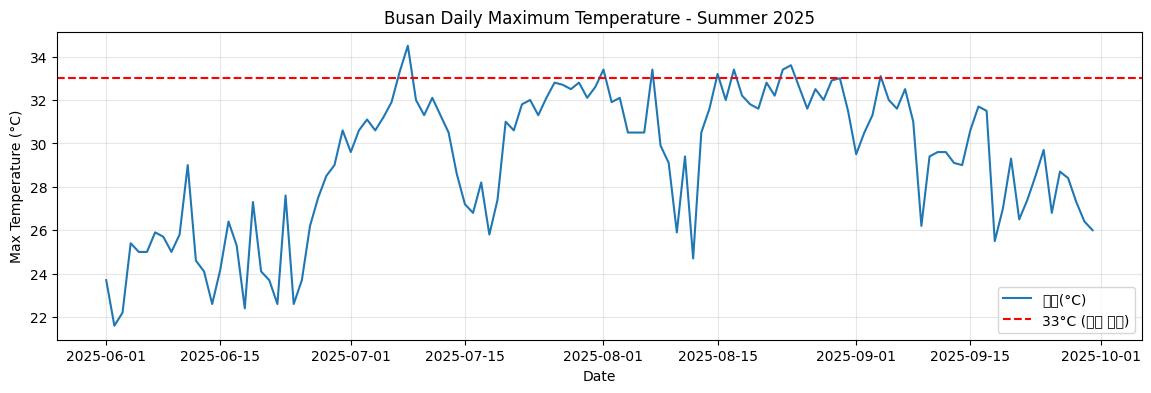

In [21]:
# 연도별 전국 일최고기온 계산
yearly_max_temp = df_summer.groupby("연도")["기온(°C)"].max().reset_index()
yearly_max_temp.columns = ["Year", "Annual Max Temp (°C)"]
display(yearly_max_temp)

# 부산 지역 기준(또는 전체 일별 최고기온) 폭염일 및 연속 지속 기간 계산
daily_max_busan = df_sample_summer.groupby(df_sample_summer["일시"].dt.date)["기온(°C)"].max()
heatwave_day = daily_max_busan >= 33
group_id = (~heatwave_day).cumsum()
heatwave_lengths = heatwave_day[heatwave_day].groupby(group_id[heatwave_day]).size()
display(heatwave_lengths)

# 부산 일별 최고기온 및 폭염 기준선 시각화
plt.figure(figsize=(14, 4))
daily_max_busan.plot()
plt.axhline(33, color="red", linestyle="--", label="33°C (폭염 기준)")
plt.title("Busan Daily Maximum Temperature - Summer 2025")
plt.xlabel("Date")
plt.ylabel("Max Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

연도별 여름철 기상 요약 (평균기온, 최고기온, 일사량)

,연도,평균기온,최고기온,평균일사량
0,2016,25.093989,37.5,1.140705
1,2017,24.852391,36.8,1.215038
2,2018,25.274283,39.4,1.267446
3,2019,24.430690,36.7,1.175559
4,2020,24.113862,36.3,1.119829
5,2021,24.879812,36.3,1.174206
6,2022,25.086526,37.1,1.165258
7,2023,25.379290,37.6,1.182975
8,2024,26.561268,36.8,1.251532
9,2025,26.283156,37.6,1.271545


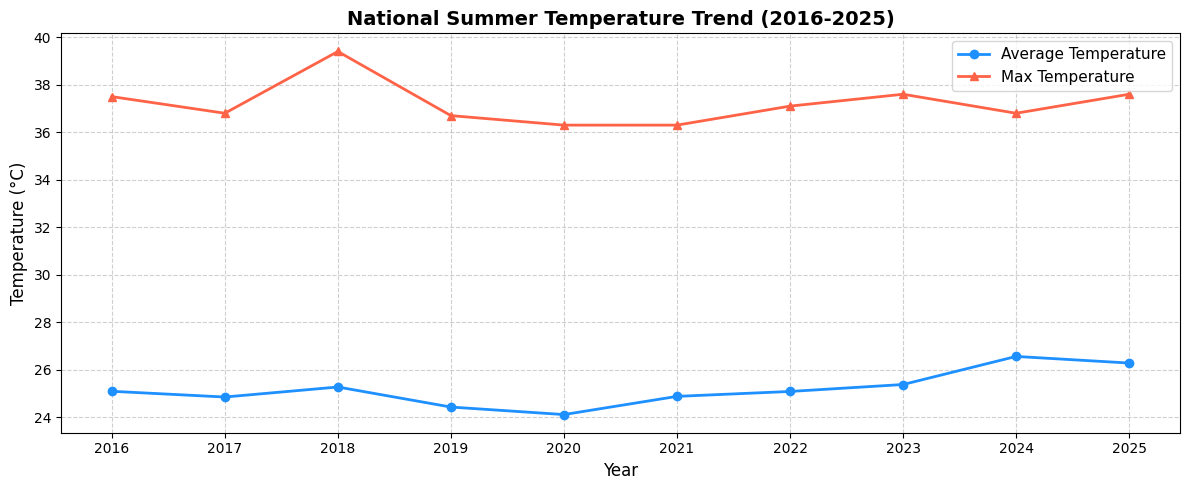

In [22]:
yearly_summary = (
    df_summer.groupby("연도")
    .agg(
        평균기온=("기온(°C)", "mean"),
        최고기온=("기온(°C)", "max"),
        평균일사량=("일사(MJ/m2)", "mean"),
    )
    .reset_index()
)
display(yearly_summary)

# 연도별 여름철 기온 변화 트렌드 시각화
plt.figure(figsize=(12, 5))
plt.plot(yearly_summary["연도"], yearly_summary["평균기온"], marker="o", color="dodgerblue", linewidth=2, label="Average Temperature")
plt.plot(yearly_summary["연도"], yearly_summary["최고기온"], marker="^", color="tomato", linewidth=2, label="Max Temperature")
plt.title("National Summer Temperature Trend (2016-2025)", fontsize=14, fontweight="bold")
plt.xlabel("Year", fontsize=12)
plt.ylabel("Temperature (°C)", fontsize=12)
plt.xticks(yearly_summary["연도"])
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

폭염일 vs 일반일 시간대별 비교(기온, 일사량)

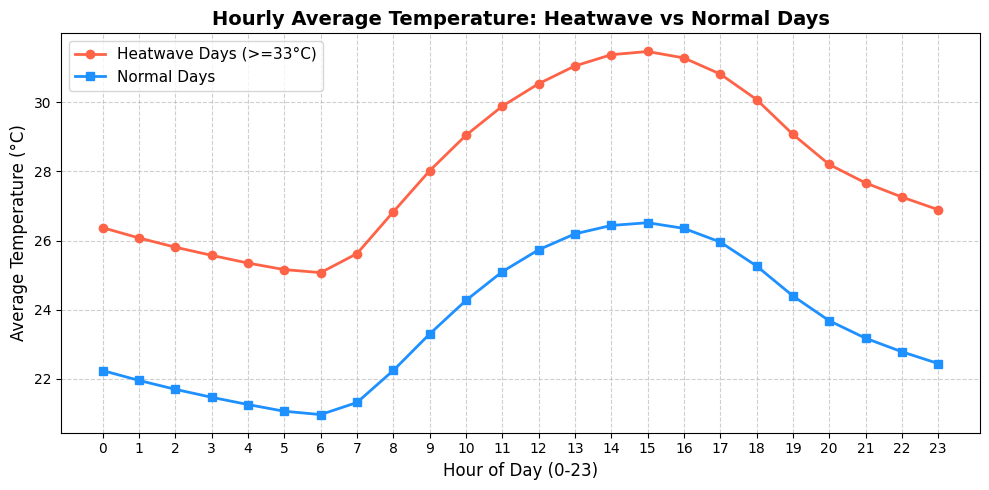

,Normal Days,Heatwave Days
시간,,
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
5,NaN,NaN
6,0.032313,0.024323
7,0.175879,0.240513
8,0.531449,0.711734


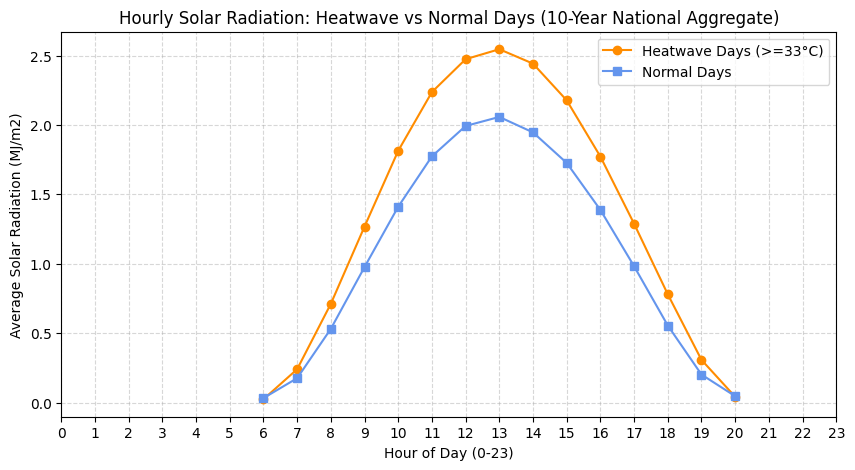

,Average Max Solar Radiation
is_heatwave,
Normal Days,3.085888
Heatwave Days,3.418558


In [23]:
# 시간대별 평균 기온 비교
hourly_temp = df_summer.groupby(["is_heatwave", "hour"])["기온(°C)"].mean().unstack(level=0)
hourly_temp.columns = ["Normal Days", "Heatwave Days"]

plt.figure(figsize=(10, 5))
plt.plot(hourly_temp.index, hourly_temp["Heatwave Days"], marker="o", color="tomato", linewidth=2, label="Heatwave Days (>=33°C)")
plt.plot(hourly_temp.index, hourly_temp["Normal Days"], marker="s", color="dodgerblue", linewidth=2, label="Normal Days")
plt.title("Hourly Average Temperature: Heatwave vs Normal Days", fontsize=14, fontweight="bold")
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Average Temperature (°C)", fontsize=12)
plt.xticks(range(0, 24))
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# 시간대별 평균 일사량 비교
hourly_solar = df_summer.groupby(["is_heatwave", "시간"])["일사(MJ/m2)"].mean().unstack(level=0)
hourly_solar.columns = ["Normal Days", "Heatwave Days"]
display(hourly_solar.head(10))

# 시간대별 평균 일사량 시각화
plt.figure(figsize=(10, 5))
plt.plot(hourly_solar.index, hourly_solar["Heatwave Days"], marker="o", color="darkorange", label="Heatwave Days (>=33°C)")
plt.plot(hourly_solar.index, hourly_solar["Normal Days"], marker="s", color="cornflowerblue", label="Normal Days")
plt.title("Hourly Solar Radiation: Heatwave vs Normal Days (10-Year National Aggregate)")
plt.xlabel("Hour of Day (0-23)")
plt.ylabel("Average Solar Radiation (MJ/m2)")
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# 최고 일사량 비교 요약
max_solar_daily = df_summer.groupby(["날짜", "is_heatwave"])["일사(MJ/m2)"].max().reset_index()
solar_comp = (
    max_solar_daily.groupby("is_heatwave")["일사(MJ/m2)"]
    .mean()
    .rename({False: "Normal Days", True: "Heatwave Days"})
    .to_frame("Average Max Solar Radiation")
)
display(solar_comp)